In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [5]:
df = pd.read_csv('noisy_curvefit_data.csv')

In [8]:
print(df.shape)
print(f"There are {df.shape[0]} rows and {df.shape[1]} columns.")
print(df.head())
print(df.tail())
print(df.columns.tolist())

(100, 6)
There are 100 rows and 6 columns.
          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850
['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']


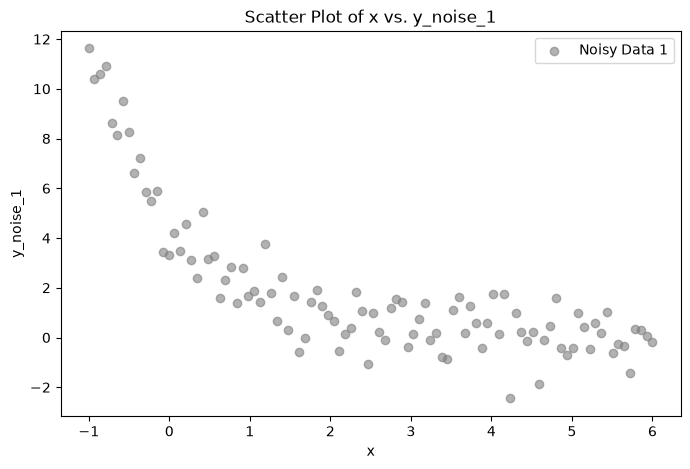

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(df['x'], df['y_noise_1'], color='gray', alpha=0.6, label='Noisy Data 1')
plt.xlabel('x')
plt.ylabel('y_noise_1')
plt.title('Scatter Plot of x vs. y_noise_1')
plt.legend()
plt.show()


Fit: y = 4.71 * e^(-0.92 * x)
Reduced Chi-Squared: 0.79


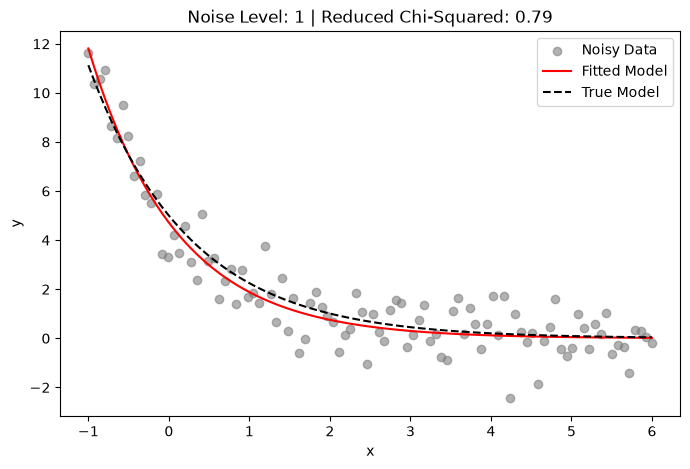

In [10]:
def model(x, A, k):
    return A * np.exp(-k * x)

x = df['x']
y_noise_1 = df['y_noise_1']

p0 = [1, 1]
popt, pcov = curve_fit(model, x, y_noise_1, p0=p0)

A_fit, k_fit = popt

print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof
print(f"Reduced Chi-Squared: {chi2_reduced:.2f}")

plt.figure(figsize=(8, 5))
plt.scatter(x, y_noise_1, color='gray', alpha=0.6, label='Noisy Data')
plt.plot(x, model(x, A_fit, k_fit), color='red', label='Fitted Model')
plt.plot(x, model(x, 5, 0.8), color='black', linestyle='--', label='True Model')
plt.title(f"Noise Level: 1 | Reduced Chi-Squared: {chi2_reduced:.2f}")
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

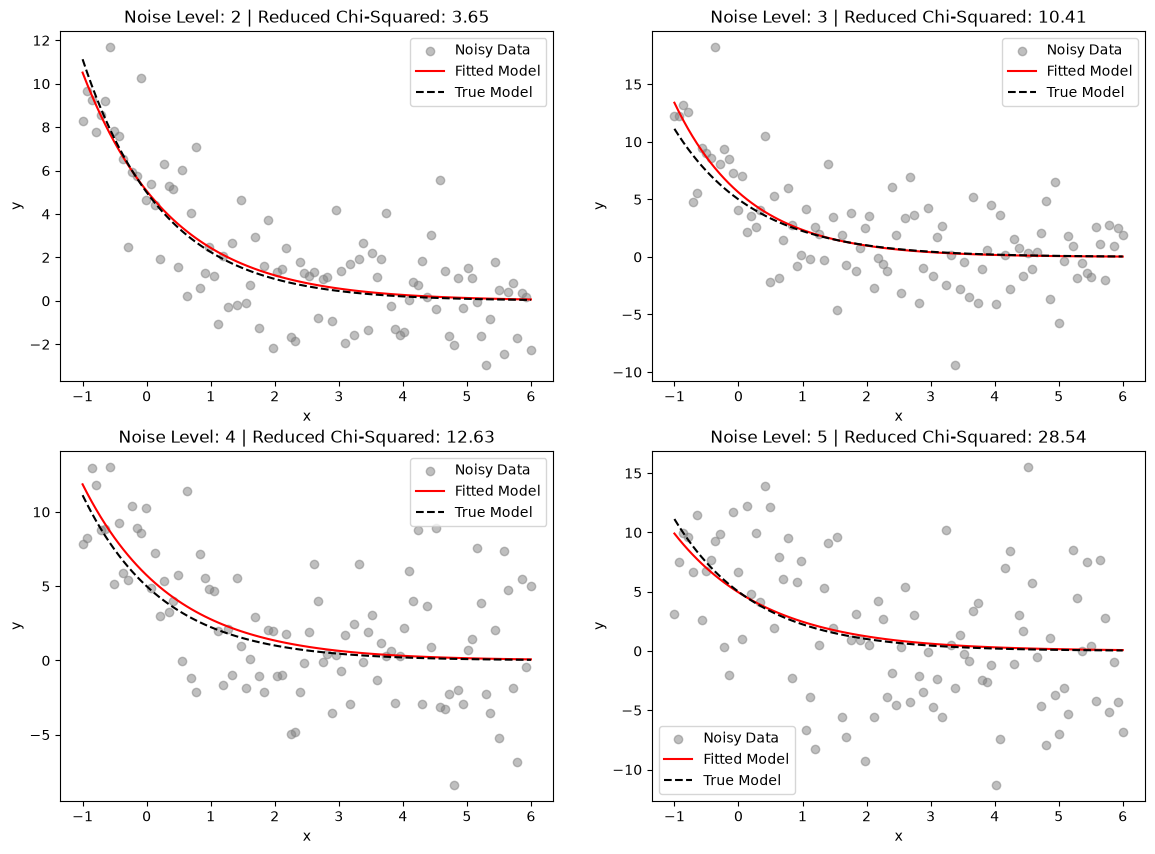

In [13]:
def fit_model(x, y):
    p0 = [1, 1]
    popt, pcov = curve_fit(model, x, y, p0=p0)
    residuals = y - model(x, *popt)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    return popt, chi2_reduced

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

noise_columns = ['y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']

for i, col_name in enumerate(noise_columns):
    ax = axes[i]
    x_data = df['x']
    y_data = df[col_name]
    noise_level = col_name.split('_')[-1] 
    
    popt, chi2_reduced = fit_model(df['x'], y_data)
    A_fit, k_fit = popt
    
    ax.scatter(x_data, y_data, color='gray', alpha=0.5, label='Noisy Data')
    ax.plot(x_data, model(x_data, A_fit, k_fit), color='red', label='Fitted Model')
    ax.plot(x_data, model(x_data, 5, 0.8), color='black', linestyle='--', label='True Model')
    ax.set_title(f"Noise Level: {noise_level} | Reduced Chi-Squared: {chi2_reduced:.2f}")
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.legend()

plt.show()

In [14]:
# as you increase the noise level, the reduced chi-squared value increases, indicating a worse fit. This is expected because higher noise levels introduce more variability in the data, making it harder for the model to accurately capture the underlying trend.

In [15]:
results_data = []
noise_columns = ['y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']

for col_name in noise_columns:
    noise_level = int(col_name.split('_')[-1])
    popt, chi2_reduced = fit_model(df['x'], df[col_name])
    results_data.append({
        'Noise level': noise_level,
        'A fit': popt[0],
        'k fit': popt[1],
        'Reduced chi-squared': chi2_reduced
    })

df_results = pd.DataFrame(results_data)
print(df_results)

df_results.to_csv("noisy_parameters.csv", index=False)

   Noise level     A fit     k fit  Reduced chi-squared
0            1  4.714814  0.918308             0.790673
1            2  5.063889  0.730396             3.649382
2            3  5.609396  0.870372            10.410207
3            4  5.738727  0.725965            12.626832
4            5  4.943458  0.695012            28.538124
